# Лабораторная работа №8. Генерация и интерполяция в латентном пространстве
**Вариант 1. Скрыпник Михаил Дмитриевич, МИК11.**

Набор «диск»; единственный фактор основной серии β: 1 → 8. d=8, 30 эпох, seed 101–105. Windows CPU float32, 4 потока. Engee не использовалась. Ниже выполняются реальные обучения; результаты демонстрации не подставляются.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
assert (ROOT/'src/lab08_experiment.py').exists(), 'Откройте блокнот из папки LR08'
sys.path.insert(0,str(ROOT/'src'))
from lab08_experiment import preregister,run_all
pre=preregister()
print(json.dumps(pre,ensure_ascii=False,indent=2))
assert [k for k in pre['A'] if pre['A'][k]!=pre['B'][k]]==['beta']

{
  "recorded_at": "2026-10-27T17:03:14+03:00",
  "variant": 1,
  "kind": "disc",
  "factor": "beta_1_to_8",
  "A": {
    "d": 8,
    "beta": 1.0,
    "interp": "lin",
    "temp": 1.0,
    "epochs": 30
  },
  "B": {
    "d": 8,
    "beta": 8.0,
    "interp": "lin",
    "temp": 1.0,
    "epochs": 30
  },
  "seeds": [
    101,
    102,
    103,
    104,
    105
  ],
  "data_seed": 7,
  "pair_seed": 11,
  "sample_seed": "1000 + training_seed",
  "hypothesis": "Увеличение beta с 1 до 8 ухудшит реконструкцию более чем на 1 дБ и уменьшит число активных осей. Предполагается улучшение интерполяции и качества сэмплов более чем на 1 дБ; изменение R2 предполагается в пределах 0,05. Эти предположения могут не подтвердиться.",
  "tolerances": {
    "recon": 1.0,
    "interp": 1.0,
    "sample": 1.0,
    "r2": 0.05
  },
  "tolerance_rationale": "1 дБ соответствует изменению MSE примерно в 1,26 раза; 0,05 R2 - пять процентных пунктов объяснённой дисперсии. Учебные пороги практической величины, не кри

## Методика
4096 обучающих и 1024 тестовых сцен, seed данных 7. Реконструкция оценивается по D(μ), интерполяция по 200 фиксированным парам при t=0.25,0.5,0.75. 256 сэмплов из N(0,I), seed=1000+seed обучения. R² — линейная регрессия факторов по μ с проверкой на тесте. Допуски записаны выше до обучения: 1 дБ и 0.05 R². Критерий 2s — учебная эвристика, а не формальный тест.

In [2]:
# Полное обучение основной серии и диагностики. Может занять 10–20 минут.
result=run_all()
for row in result['summary']:print(json.dumps(row,ensure_ascii=False))

2026-10-27T17:03:15+03:00 PREREGISTRATION {"recorded_at": "2026-10-27T17:03:14+03:00", "variant": 1, "kind": "disc", "factor": "beta_1_to_8", "A": {"d": 8, "beta": 1.0, "interp": "lin", "temp": 1.0, "epochs": 30}, "B": {"d": 8, "beta": 8.0, "interp": "lin", "temp": 1.0, "epochs": 30}, "seeds": [101, 102, 103, 104, 105], "data_seed": 7, "pair_seed": 11, "sample_seed": "1000 + training_seed", "hypothesis": "Увеличение beta с 1 до 8 ухудшит реконструкцию более чем на 1 дБ и уменьшит число активных осей. Предполагается улучшение интерполяции и качества сэмплов более чем на 1 дБ; изменение R2 предполагается в пределах 0,05. Эти предположения могут не подтвердиться.", "tolerances": {"recon": 1.0, "interp": 1.0, "sample": 1.0, "r2": 0.05}, "tolerance_rationale": "1 дБ соответствует изменению MSE примерно в 1,26 раза; 0,05 R2 - пять процентных пунктов объяснённой дисперсии. Учебные пороги практической величины, не критерий проверки гипотез.", "active_axis_rule": "mean_test KL_j > 0.05 nat; mu.

2026-10-27T17:03:15+03:00 ENVIRONMENT {"recorded_at": "2026-10-27T17:03:15+03:00", "platform": "Windows-10-10.0.26300-SP0", "python": "3.11.17 (main, Oct  3 2026, 01:03:09) [MSC v.1944 64 bit (AMD64)]", "executable": "C:\\DONSTU\\ai-in-creative-industries\\LR05\\.venv\\Scripts\\python.exe", "device": "cpu", "threads": 4, "dtype": "float32", "deterministic_algorithms": true, "packages": {"torch": "2.11.0+cpu", "numpy": "2.4.6", "Pillow": "12.3.0", "nbformat": "5.11.1", "nbclient": "0.11.0"}, "libraries": {"lab07_lib.py": "3455ac72c7d5a0a119784faefd6c248f8c81975f99beba1dd26dca1052a89a03", "lab08_lib.py": "dd7c4983f21c5d11edcd4eb740eb5de4130b299d67507f07d03ecb4751060043"}}


2026-10-27T17:03:16+03:00 BASELINE mean training image, test PSNR=17.170731


2026-10-27T17:03:16+03:00 START A beta=1 seed=101 warmup=10 epochs=30


2026-10-27T17:03:55+03:00 END A seed=101: recon=26.698673, interp=22.810677, sample=23.484440, r2=0.905241; active=6; seconds=38.963


...

2026-10-27T17:14:03+03:00 WARMUP CHECK no_warmup recon=[26.4734, 17.1578, 25.6636, 26.2241, 25.7498]


2026-10-27T17:14:03+03:00 WARMUP CHECK main A recon=[26.6987, 26.8902, 25.717, 26.8632, 25.6705]


2026-10-27T17:14:03+03:00 COMPLETE: 10 main models + 1 AE + 5 no-warmup; measured, checkpointed, figures saved


{"metric": "recon", "A": 26.367914962768555, "s": 0.619989396481809, "B": 22.410313034057616, "delta": -3.9576019287109396, "ratio": 6.383338087987863, "criterion_2s": true, "tolerance": 1.0, "classification": "ухудшение", "outside_tolerance": true}


{"metric": "interp", "A": 22.64804916381836, "s": 0.3937653219896878, "B": 21.98850491841634, "delta": -0.6595442454020208, "ratio": 1.6749678261898682, "criterion_2s": false, "tolerance": 1.0, "classification": "нейтрально", "outside_tolerance": false}
{"metric": "sample", "A": 23.303030014038086, "s": 0.5350514718265535, "B": 23.258741760253905, "delta": -0.04428825378418111, "ratio": 0.08277381918601269, "criterion_2s": false, "tolerance": 1.0, "classification": "нейтрально", "outside_tolerance": false}
{"metric": "r2", "A": 0.9022359013557434, "s": 0.019239019714570583, "B": 0.8183146953582764, "delta": -0.083921205997467, "ratio": 4.3620312907060255, "criterion_2s": true, "tolerance": 0.05, "classification": "ухудшение", "outside_tolerance": true}


## Проверка сохранённых весов
Повторный расчёт четырёх метрик и диагностики для всех 16 сохранённых моделей. Выполняется отдельным модулем.

In [3]:
from verify_artifacts import verify
verify()

PASS A seed=101: 4 metrics and 8-axis diagnostics recomputed from checkpoint


PASS B seed=101: 4 metrics and 8-axis diagnostics recomputed from checkpoint


PASS A seed=102: 4 metrics and 8-axis diagnostics recomputed from checkpoint


PASS B seed=102: 4 metrics and 8-axis diagnostics recomputed from checkpoint


PASS A seed=103: 4 metrics and 8-axis diagnostics recomputed from checkpoint


...

PASS NO_WARMUP seed=103: 4 metrics and 8-axis diagnostics recomputed from checkpoint


PASS NO_WARMUP seed=104: 4 metrics and 8-axis diagnostics recomputed from checkpoint


PASS NO_WARMUP seed=105: 4 metrics and 8-axis diagnostics recomputed from checkpoint


PASS: data hash, preregistration timing, one changed factor, five seeds, summary, baseline, 16 checkpoints


True

## Визуальные результаты
Сэмплы AE/A/B, истинный путь в пространстве факторов, интерполяция A/B. Пара 0 → 2, seed 101, восемь точек пути. Выбор пары фиксирован методичкой.

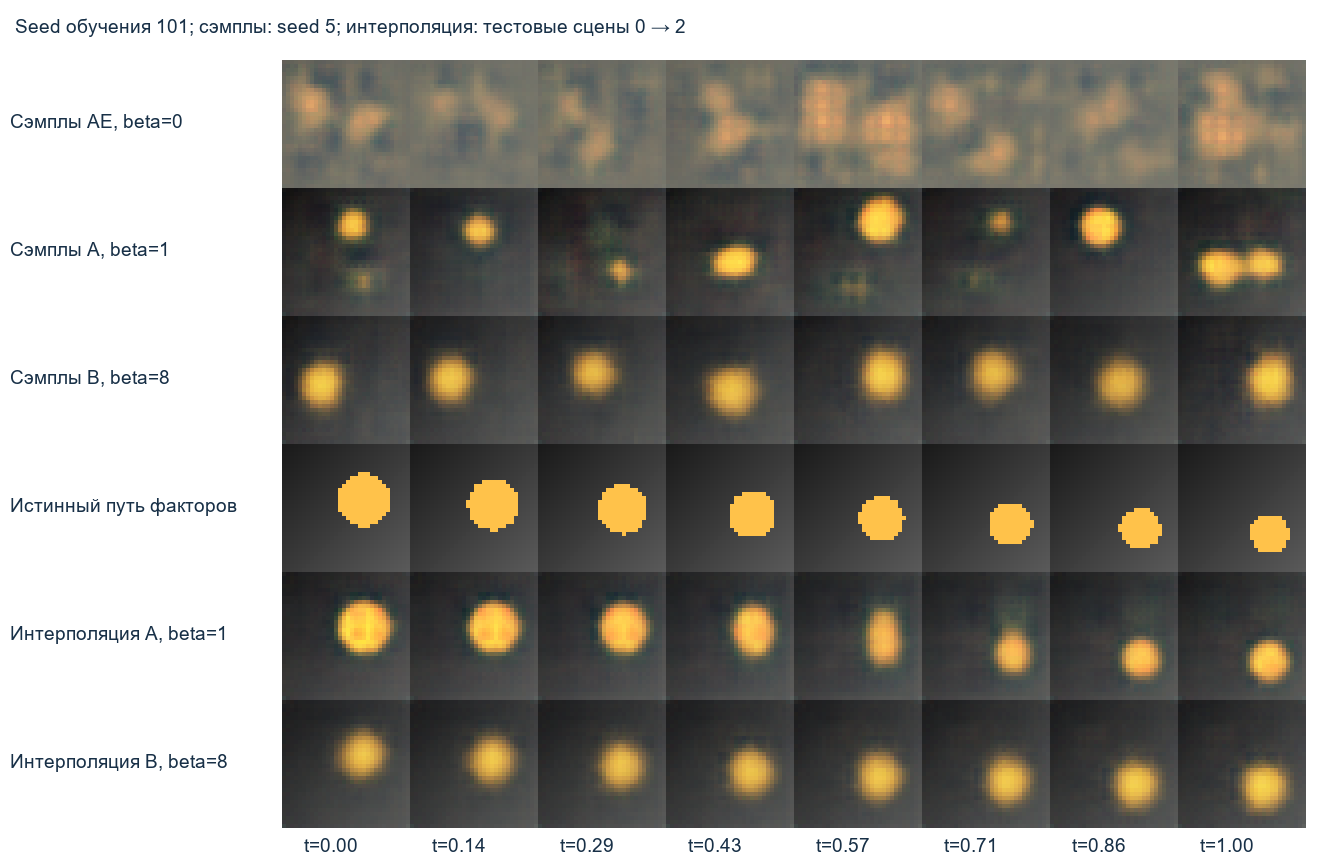

Реконструкции: оригинал / A / B


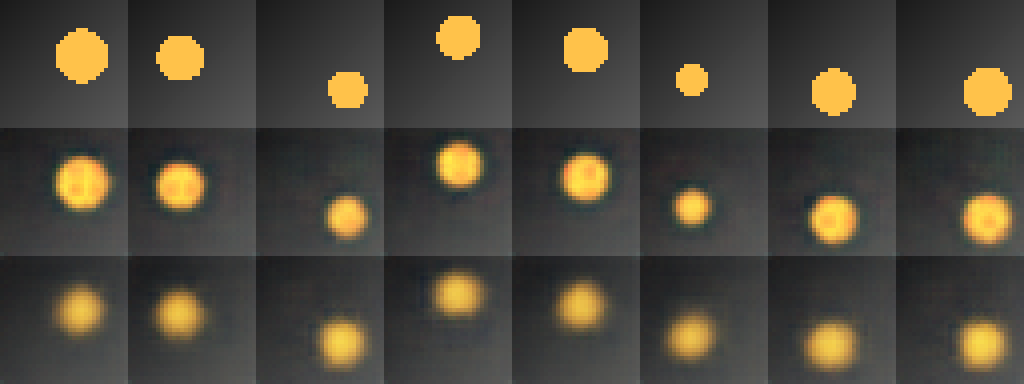

In [4]:
from PIL import Image
from IPython.display import display
display(Image.open(ROOT/'artifacts/comparison_labeled.png'))
print('Реконструкции: оригинал / A / B')
display(Image.open(ROOT/'artifacts/reconstructions.png'))

## Диагностика и чувствительность к допускам
Ось активна при среднем KL_j > 0.05 нат. Для AE logvar не обучается: число активных осей по KL не интерпретируется.

In [5]:
for mode in ['A','B']:
    for r in result['measurements']:
        if r['mode']==mode:print(mode,r['seed'],'active=',r['diagnostics']['active_axes'],'mu_std=',r['diagnostics']['mu_std'])
for r in result['summary']:
    print(r['metric'],r['classification'],'2s=',r['criterion_2s'],'outside=',{k:abs(r['delta'])>k*r['tolerance'] for k in [0.5,1,2]})
print('AE seed101:',result['ae']['metrics'])
print('Без разогрева:',[(r['seed'],r['metrics']['recon'],r['diagnostics']['active_axes']) for r in result['no_warmup']])

A 101 active= 6 mu_std= [1.002448320388794, 0.95516437292099, 0.07395895570516586, 0.9002415537834167, 0.07288681715726852, 1.000067949295044, 1.0016942024230957, 0.9772768020629883]
A 102 active= 5 mu_std= [0.9981042742729187, 1.076798915863037, 1.04606032371521, 0.10365032404661179, 0.039032936096191406, 0.9294599294662476, 0.9324269890785217, 0.03998670354485512]
A 103 active= 8 mu_std= [0.9456468820571899, 1.0462000370025635, 0.4191335439682007, 0.9491993188858032, 0.9628679156303406, 0.9825552701950073, 1.0275465250015259, 0.41802284121513367]
A 104 active= 6 mu_std= [0.9955984950065613, 0.7549654245376587, 0.9862641096115112, 1.0305519104003906, 0.064824678003788, 0.057393159717321396, 0.8099648952484131, 1.0472089052200317]
A 105 active= 6 mu_std= [0.9789481163024902, 0.20345894992351532, 1.0242278575897217, 0.990236222743988, 1.0429166555404663, 1.0277271270751953, 0.08495871722698212, 0.8781463503837585]
B 101 active= 2 mu_std= [0.06710972636938095, 0.1277003288269043, 0.90039

## Вывод и ограничения
Численный и визуальный анализ, сравнение с демонстрацией и ответы на 10 вопросов приведены в отчёте. Сэмплы оцениваются по близости к тесту, разнообразие этим не доказано. Активность осей зависит от порога; R² не доказывает независимость осей. Обобщение на реальные изображения, другие архитектуры и Engee не проверено. Полный паспорт — artifacts/passport.json; фактический журнал — reports/training_log.txt.